In [1]:
import pandas as pd

drug_gene_df = pd.read_csv(r"C:\tri_disease_project\results\tables\dgidb_hub_gene_interactions.csv")

# find drugs that interact with more than one hub gene
drug_target_counts = drug_gene_df.groupby('drug').agg(
    n_hub_genes_targeted=('gene', 'nunique'),
    genes_targeted=('gene', lambda x: ', '.join(sorted(set(x)))),
    fda_approved=('fda_approved', 'max')
).sort_values('n_hub_genes_targeted', ascending=False)

multi_target_drugs = drug_target_counts[drug_target_counts['n_hub_genes_targeted'] >= 2]

print("Total unique drugs:", drug_target_counts.shape[0])
print("Multi-hub-gene-targeting drugs:", multi_target_drugs.shape[0])
print("\nTop 20 multi-target repurposing candidates:")
print(multi_target_drugs.head(20).to_string())

multi_target_drugs.to_csv(r"C:\tri_disease_project\results\tables\multi_target_drugs.csv")

Total unique drugs: 1451
Multi-hub-gene-targeting drugs: 230

Top 20 multi-target repurposing candidates:
                           n_hub_genes_targeted                             genes_targeted  fda_approved
drug                                                                                                    
DOXORUBICIN HYDROCHLORIDE                     7  BCL2, BDNF, CCND1, ESR1, LPL, SMAD3, TP53          True
CISPLATIN                                     7    BCL2, CCND1, ESR1, IL6, PTEN, TNF, TP53          True
DOCETAXEL ANHYDROUS                           6           BCL2, ESR1, IL6, PTEN, TNF, TP53          True
GOSSYPOL                                      5             BCL2, CCND1, ESR1, SMAD3, TP53         False
TROGLITAZONE                                  5              APOE, BDNF, CCND1, LEP, PPARG          True
DIETHYLSTILBESTROL                            4                     BCL2, BDNF, ESR1, TP53          True
ALPELISIB                                     4       

Real network: 374 nodes, 983 edges, clustering coefficient = 0.2864

Random networks (n=1000): mean clustering = 0.0421 ± 0.0064

Z-score: 38.31
Empirical p-value: <0.001 (0/1000 random networks matched or exceeded real network)


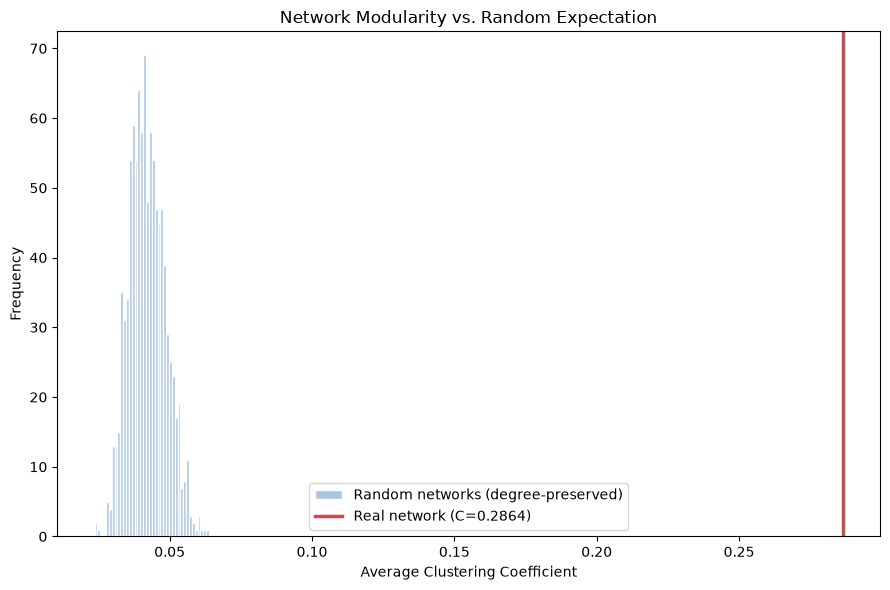

In [2]:
import networkx as nx
import re
import numpy as np

edges = pd.read_csv(r"C:\tri_disease_project\results\tables\lcc_edges.csv")

def parse_edge(name):
    match = re.match(r"(\S+)\s+\(pp\)\s+(\S+)", name)
    return (match.group(1), match.group(2)) if match else (None, None)

edges[['source', 'target']] = edges['name'].apply(lambda x: pd.Series(parse_edge(x)))
edges = edges.dropna(subset=['source', 'target'])

G = nx.from_pandas_edgelist(edges, source='source', target='target')
real_clustering = nx.average_clustering(G)
real_n, real_m = G.number_of_nodes(), G.number_of_edges()

print(f"Real network: {real_n} nodes, {real_m} edges, clustering coefficient = {real_clustering:.4f}")

# generate 1000 random networks preserving the same degree sequence (configuration model)
np.random.seed(42)
random_clusterings = []
degree_sequence = [d for n, d in G.degree()]

for i in range(1000):
    try:
        G_random = nx.configuration_model(degree_sequence, seed=i)
        G_random = nx.Graph(G_random)  # remove multi-edges/self-loops
        G_random.remove_edges_from(nx.selfloop_edges(G_random))
        random_clusterings.append(nx.average_clustering(G_random))
    except:
        continue

random_clusterings = np.array(random_clusterings)
print(f"\nRandom networks (n={len(random_clusterings)}): mean clustering = {random_clusterings.mean():.4f} ± {random_clusterings.std():.4f}")

z_score = (real_clustering - random_clusterings.mean()) / random_clusterings.std()
p_value = (random_clusterings >= real_clustering).sum() / len(random_clusterings)

print(f"\nZ-score: {z_score:.2f}")
print(f"Empirical p-value: {p_value:.4f}" if p_value > 0 else "Empirical p-value: <0.001 (0/1000 random networks matched or exceeded real network)")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 6))
ax.hist(random_clusterings, bins=40, color='#A9C4E5', edgecolor='white', label='Random networks (degree-preserved)')
ax.axvline(real_clustering, color='#C44E52', linewidth=2.5, label=f'Real network (C={real_clustering:.4f})')
ax.set_xlabel('Average Clustering Coefficient')
ax.set_ylabel('Frequency')
ax.set_title('Network Modularity vs. Random Expectation')
ax.legend()
plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig_extra_random_network.png", dpi=300, bbox_inches='tight')
plt.show()

In [3]:
import requests
import pandas as pd
import time

hub_genes = pd.read_csv(r"C:\tri_disease_project\results\tables\hub_genes_final.csv")['gene_symbol'].tolist()

# Step 1: resolve gene symbols to GENCODE IDs
gencode_map = {}
for gene in hub_genes:
    resp = requests.get(
        "https://gtexportal.org/api/v2/reference/gene",
        params={"geneId": gene, "gencodeVersion": "v26", "genomeBuild": "GRCh38/hg38"}
    )
    if resp.status_code == 200:
        data = resp.json()
        if data.get('data'):
            gencode_map[gene] = data['data'][0]['gencodeId']
    time.sleep(0.2)

print("Resolved genes:", len(gencode_map), "/", len(hub_genes))
print(gencode_map)

Resolved genes: 17 / 17
{'PPARG': 'ENSG00000132170.19', 'TNF': 'ENSG00000232810.3', 'ESR1': 'ENSG00000091831.22', 'IL6': 'ENSG00000136244.11', 'TP53': 'ENSG00000141510.16', 'APOE': 'ENSG00000130203.9', 'PTEN': 'ENSG00000171862.10', 'BCL2': 'ENSG00000171791.12', 'IGF1': 'ENSG00000017427.15', 'LEP': 'ENSG00000174697.4', 'LPL': 'ENSG00000175445.14', 'CCND1': 'ENSG00000110092.3', 'CD4': 'ENSG00000010610.9', 'PIK3R1': 'ENSG00000145675.14', 'SMAD3': 'ENSG00000166949.15', 'PPARGC1A': 'ENSG00000109819.8', 'BDNF': 'ENSG00000176697.18'}


In [4]:
records = []
for gene, gencode_id in gencode_map.items():
    resp = requests.get(
        "https://gtexportal.org/api/v2/expression/medianGeneExpression",
        params={"gencodeId": gencode_id, "datasetId": "gtex_v10", "itemsPerPage": 100}
    )
    if resp.status_code == 200:
        data = resp.json().get('data', [])
        for entry in data:
            records.append({
                'gene': gene,
                'tissue': entry['tissueSiteDetailId'],
                'median_tpm': entry['median']
            })
    time.sleep(0.2)

expr_df = pd.DataFrame(records)
print("Total records:", len(expr_df))
print(expr_df.head())

# focus on tissues most relevant to hypertension, obesity, T2D
relevant_tissues = ['Adipose_Subcutaneous', 'Adipose_Visceral_Omentum', 'Pancreas', 'Liver',
                     'Artery_Aorta', 'Artery_Coronary', 'Artery_Tibial', 'Heart_Left_Ventricle',
                     'Kidney_Cortex', 'Muscle_Skeletal', 'Whole_Blood']

expr_relevant = expr_df[expr_df['tissue'].isin(relevant_tissues)]
pivot = expr_relevant.pivot(index='gene', columns='tissue', values='median_tpm')

print("\nPivoted expression matrix:")
print(pivot)

pivot.to_csv(r"C:\tri_disease_project\results\tables\gtex_hub_gene_tissue_expression.csv")

Total records: 0
Empty DataFrame
Columns: []
Index: []


KeyError: 'tissue'

In [5]:
resp = requests.get(
    "https://gtexportal.org/api/v2/expression/medianGeneExpression",
    params={"gencodeId": "ENSG00000132170.19", "datasetId": "gtex_v10", "itemsPerPage": 100}
)
print("Status:", resp.status_code)
print(resp.text[:2000])

Status: 200
{"data":[],"paging_info":{"numberOfPages":0,"page":0,"maxItemsPerPage":100,"totalNumberOfItems":0}}


In [6]:
resp = requests.get(
    "https://gtexportal.org/api/v2/expression/medianGeneExpression",
    params={"gencodeId": "ENSG00000132170.19", "datasetId": "gtex_v8", "itemsPerPage": 100}
)
print("gtex_v8 status:", resp.status_code)
print(resp.text[:1500])

# also check what datasets are actually available
resp2 = requests.get("https://gtexportal.org/api/v2/dataset/info")
print("\nDataset info status:", resp2.status_code)
print(resp2.text[:1500])

gtex_v8 status: 200
{"data":[{"median":111.145,"tissueSiteDetailId":"Adipose_Subcutaneous","ontologyId":"UBERON:0002190","datasetId":"gtex_v8","gencodeId":"ENSG00000132170.19","geneSymbol":"PPARG","unit":"TPM"},{"median":100.821,"tissueSiteDetailId":"Adipose_Visceral_Omentum","ontologyId":"UBERON:0010414","datasetId":"gtex_v8","gencodeId":"ENSG00000132170.19","geneSymbol":"PPARG","unit":"TPM"},{"median":2.81662,"tissueSiteDetailId":"Adrenal_Gland","ontologyId":"UBERON:0002369","datasetId":"gtex_v8","gencodeId":"ENSG00000132170.19","geneSymbol":"PPARG","unit":"TPM"},{"median":4.4123,"tissueSiteDetailId":"Artery_Aorta","ontologyId":"UBERON:0001496","datasetId":"gtex_v8","gencodeId":"ENSG00000132170.19","geneSymbol":"PPARG","unit":"TPM"},{"median":11.6175,"tissueSiteDetailId":"Artery_Coronary","ontologyId":"UBERON:0001621","datasetId":"gtex_v8","gencodeId":"ENSG00000132170.19","geneSymbol":"PPARG","unit":"TPM"},{"median":4.44729,"tissueSiteDetailId":"Artery_Tibial","ontologyId":"UBERON:00

In [7]:
records = []
for gene, gencode_id in gencode_map.items():
    resp = requests.get(
        "https://gtexportal.org/api/v2/expression/medianGeneExpression",
        params={"gencodeId": gencode_id, "datasetId": "gtex_v8", "itemsPerPage": 100}
    )
    if resp.status_code == 200:
        data = resp.json().get('data', [])
        for entry in data:
            records.append({
                'gene': gene,
                'tissue': entry['tissueSiteDetailId'],
                'median_tpm': entry['median']
            })
    time.sleep(0.2)

expr_df = pd.DataFrame(records)
print("Total records:", len(expr_df))
print(expr_df.head())

relevant_tissues = ['Adipose_Subcutaneous', 'Adipose_Visceral_Omentum', 'Pancreas', 'Liver',
                     'Artery_Aorta', 'Artery_Coronary', 'Artery_Tibial', 'Heart_Left_Ventricle',
                     'Kidney_Cortex', 'Muscle_Skeletal', 'Whole_Blood']

expr_relevant = expr_df[expr_df['tissue'].isin(relevant_tissues)]
pivot = expr_relevant.pivot(index='gene', columns='tissue', values='median_tpm')

print("\nPivoted expression matrix:")
print(pivot)

pivot.to_csv(r"C:\tri_disease_project\results\tables\gtex_hub_gene_tissue_expression.csv")

Total records: 918
    gene                    tissue  median_tpm
0  PPARG      Adipose_Subcutaneous   111.14500
1  PPARG  Adipose_Visceral_Omentum   100.82100
2  PPARG             Adrenal_Gland     2.81662
3  PPARG              Artery_Aorta     4.41230
4  PPARG           Artery_Coronary    11.61750

Pivoted expression matrix:
tissue    Adipose_Subcutaneous  Adipose_Visceral_Omentum  Artery_Aorta  \
gene                                                                     
APOE                430.409000                262.706000     94.080900   
BCL2                 10.629700                  7.999400      8.190470   
BDNF                  0.145097                  0.324943      2.652360   
CCND1                59.564800                 28.016600     87.221500   
CD4                  34.575700                 26.912100     18.157500   
ESR1                  2.067900                  1.574710      2.719000   
IGF1                 19.663500                 29.437200      6.276830   
IL6  

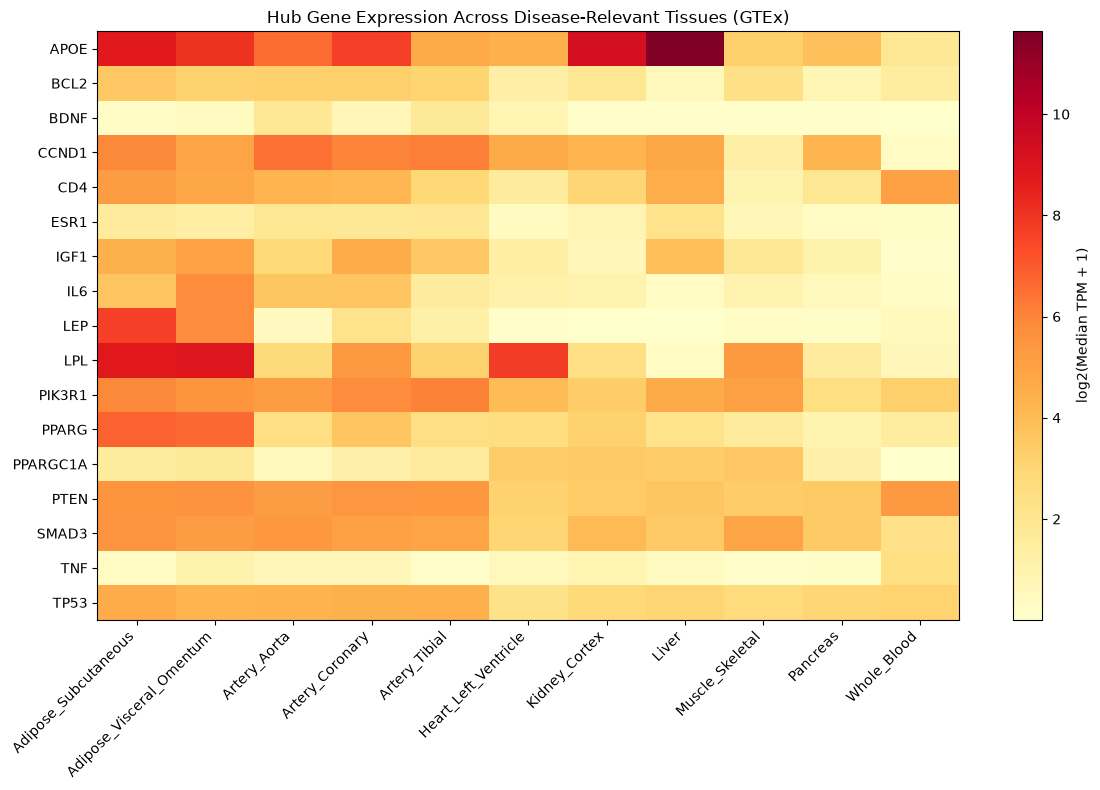

In [8]:
import numpy as np
import matplotlib.pyplot as plt

log_pivot = np.log2(pivot + 1)

fig, ax = plt.subplots(figsize=(12, 8))
im = ax.imshow(log_pivot.values, cmap='YlOrRd', aspect='auto')

ax.set_xticks(range(len(log_pivot.columns)))
ax.set_xticklabels(log_pivot.columns, rotation=45, ha='right')
ax.set_yticks(range(len(log_pivot.index)))
ax.set_yticklabels(log_pivot.index)

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('log2(Median TPM + 1)')

ax.set_title('Hub Gene Expression Across Disease-Relevant Tissues (GTEx)')
plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig_extra_gtex_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()